<a href="https://colab.research.google.com/github/laksh-ops/EVerse/blob/main/everse.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

22050,1,5.333378684807256
22050,1,45.844897959183676
22050,1,119.87591836734694


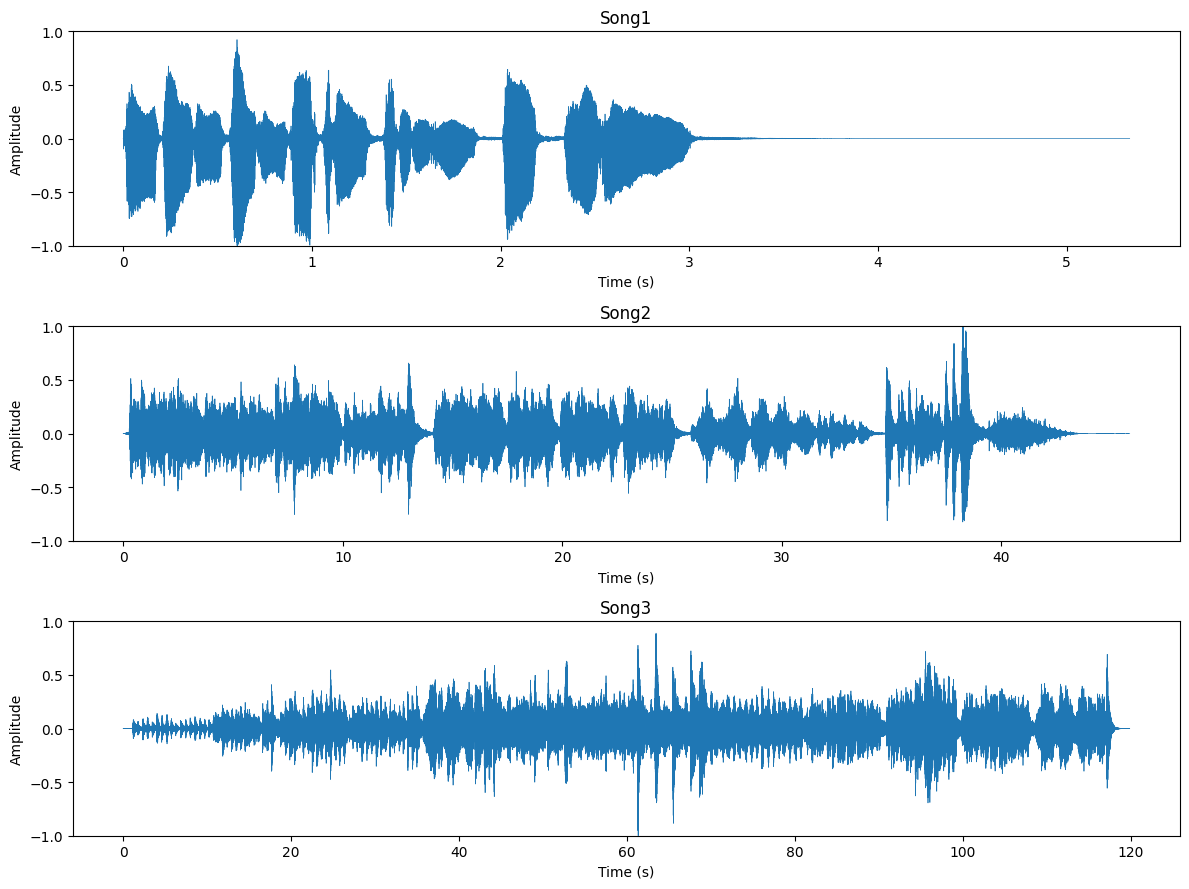

sample_count=512: window = 23 ms, frequency resolution = 43.1 Hz, time between columns = 5.8 ms
sample_count=2048: window = 93 ms, frequency resolution = 10.8 Hz, time between columns = 23.2 ms
sample_count=4096: window = 186 ms, frequency resolution = 5.4 Hz, time between columns = 46.4 ms


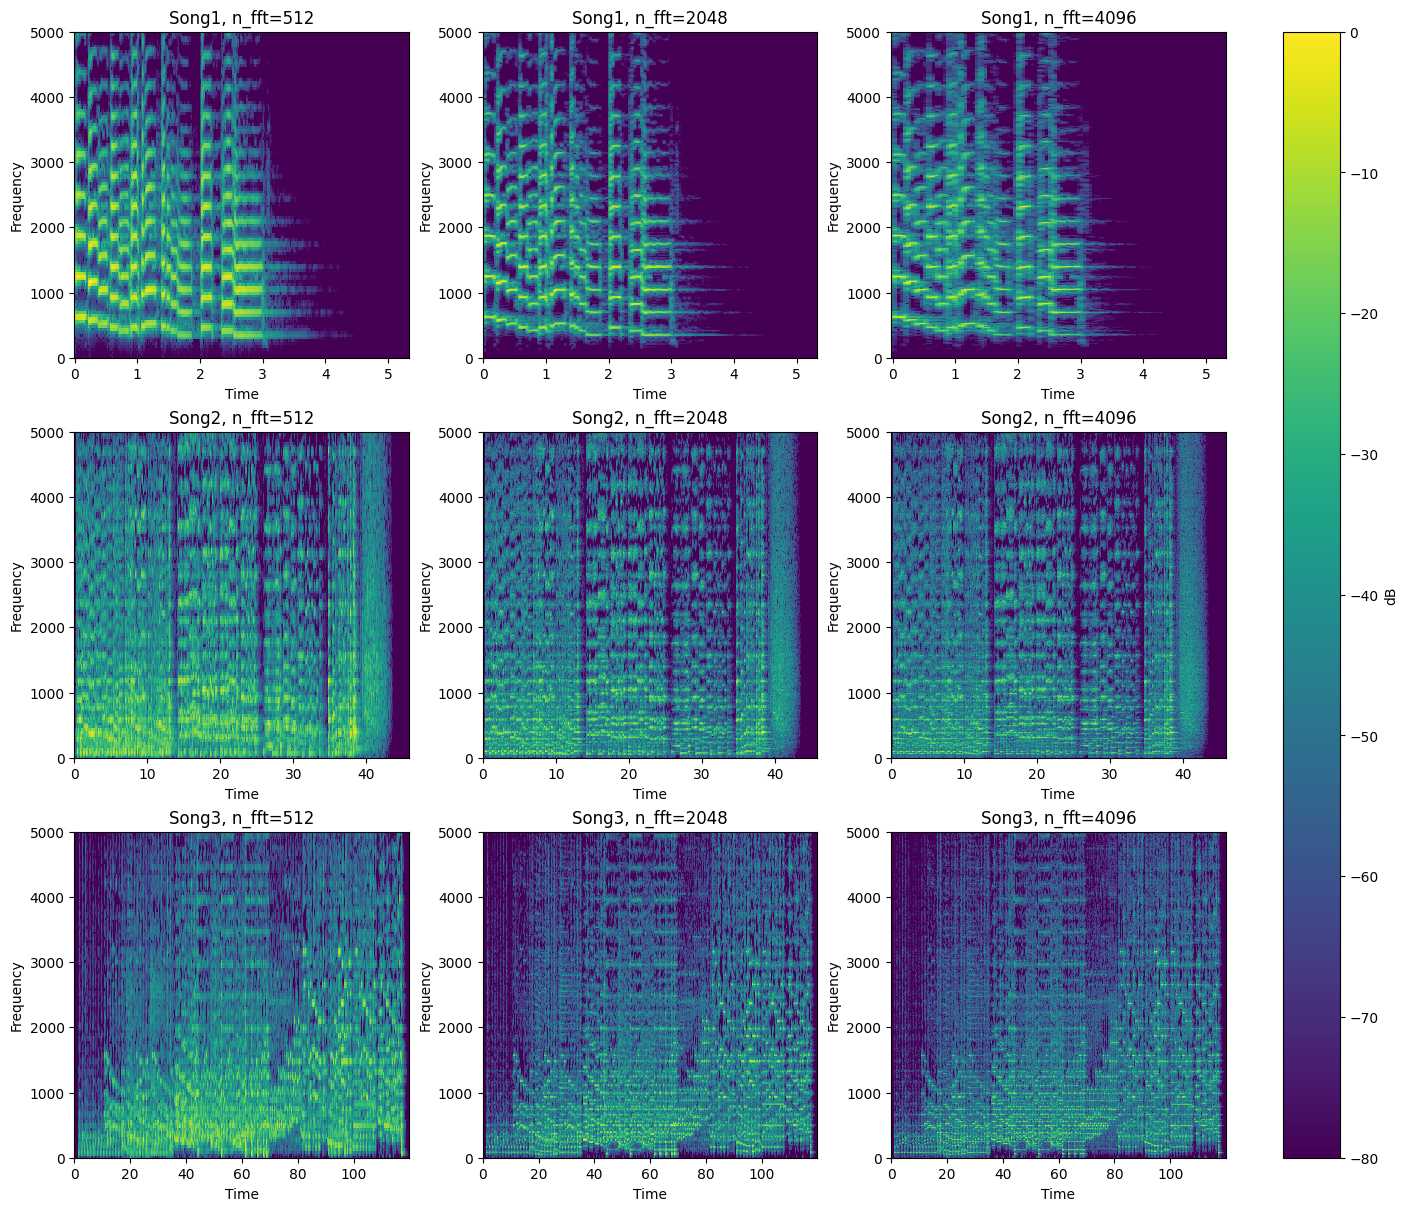

Song1: 92 peaks detected
Song2: 1346 peaks detected
Song3: 2395 peaks detected


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


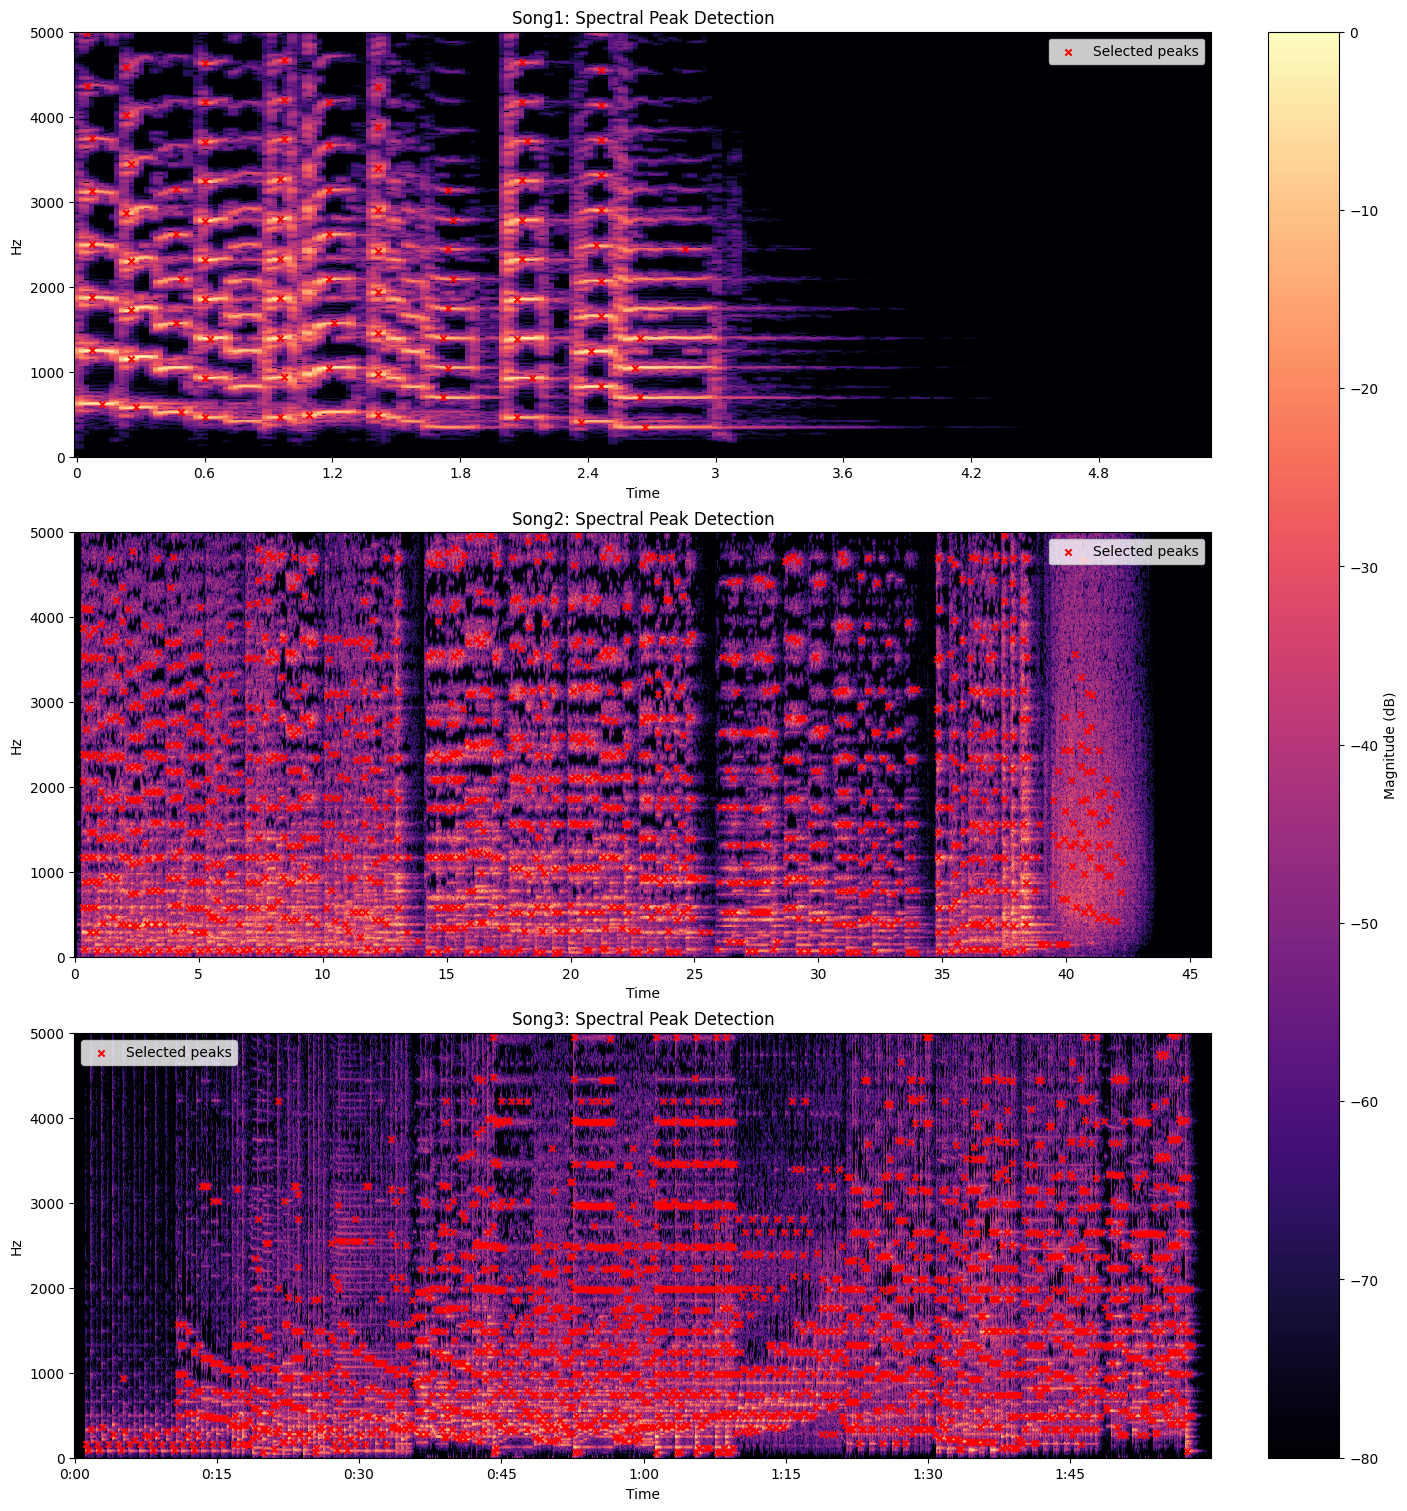


Threshold = -50 dB
Song1: 105 peaks
Song2: 1673 peaks
Song3: 4145 peaks

Threshold = -35 dB
Song1: 92 peaks
Song2: 1346 peaks
Song3: 2395 peaks

Threshold = -20 dB
Song1: 67 peaks
Song2: 507 peaks
Song3: 1095 peaks

Frequency spacing = 100 Hz, time spacing = 0.05 seconds
Song1: 154 peaks
Song2: 3114 peaks
Song3: 5742 peaks

Frequency spacing = 200 Hz, time spacing = 0.1 seconds
Song1: 92 peaks
Song2: 1346 peaks
Song3: 2395 peaks

Frequency spacing = 400 Hz, time spacing = 0.2 seconds
Song1: 46 peaks
Song2: 425 peaks
Song3: 922 peaks


In [ ]:
import numpy as np
import librosa
import matplotlib.pyplot as plt

t_srate = 22050

paths = {
    "Song1": librosa.ex('trumpet'),
    "Song2": librosa.ex('brahms'),
    "Song3": librosa.ex('nutcracker')
}

def inspect(path):
  y ,srate = librosa.load(path,sr=None,mono=False)
  #mono = False retains the og file's multi channel data and sr=None also preserves the og audio's srate

  dur = librosa.get_duration(y=y,sr = srate)
  # dur = y.shape[-1]/srate also works as shape[-1] gives the number of samples which when divided by srate gives the duration

  channels = y.shape[0] if y.ndim > 1 else 1
  #y has two dimensions if the file is stereo (channlels, samples) & one if the audio is mono the ifelse condition is for if the file is mono then shape[0]
  #gives the sample which is in the millions which will give deceptive results


  return srate,channels,dur

def load(path,target_srate = t_srate , normalize = True):
  y,srate = librosa.load(path,sr=None,mono=False)

  if y.ndim > 1 :
    # mostly efficiency nothing else as each step which uses y_mono now only handles a 1D structure and needs to compute less.(can skip)
    y_mono = librosa.to_mono(y)
  else:
    y_mono = y

  if srate!=target_srate:
    #resample takes in the audio file and changes the sampling rate, we set the target at 22050 Hz for uniformity across code
    y_resampled = librosa.resample(y_mono,orig_sr=srate,target_sr=target_srate)
  else:
    y_resampled = y_mono
  if normalize:
    peak = np.max(np.abs(y_resampled))
    if peak>0:
      y_resampled = y_resampled/peak
      #just to normalise the audio so that the loudest sample is exacly at height 1, improves consistency and also doesn't change the overall audio as each sample is multiplied by the same factor

  return y_resampled,target_srate
songs = {}
for name,path in paths.items():
  srate,channels,dur  = inspect(path)
  print(f"{srate},{channels},{dur}")
  y,sr = load(path)
  songs[name] = (y,sr)

#this creates a blankspace where we can plot the graph
fig, axes = plt.subplots(len(songs), 1, figsize=(12, 3 * len(songs)))

#ax(ax is the commonly used term, like how we use name use head pointer for linked lists) represents a plot area,(for 3 plots) it is the top most area for the first iteration, middle for the second and bottom for the third
#for each iteration the plot area has its own axes named t and y,here (t is basically the time axis, y is the audio data)
for ax, (name, (y, sr)) in zip(axes, songs.items()):
    # time axis: sample index divided by samples per second gives seconds
    t = np.arange((y.shape[0])) / sr
    ax.plot(t, y, linewidth=0.5)
    ax.set_title(name)
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Amplitude")
    #we do a y limit to fix a vertical scale so that song peaks can directly be compared
    ax.set_ylim(-1, 1)

plt.tight_layout()
plt.show()

#Group 1 Task 2


#sample_count is basically the no. of samples in a window(basically a slice of the audio data) and hop_length basically describes the distance between the starting of windows
#we keep the windows overlapping to prevent losses, as end to end joining may cause some discrepancies
def comp_spectrogram(y, sample_count= 2048,hop_length= 512):

  #this is basically a way to perform stft(short-time fourier transform) in python to convert a signal from time domain to complex time-frequency domain, y_stft will basically be a complex-valued matrix
  y_stft = librosa.stft(y,n_fft=sample_count,hop_length=hop_length)

  #just keeping each frequency's strength and throwing away the phase
  y_mag = np.abs(y_stft)

  # we use the max as the ref, hence the max value is set to be 0, this makes the quiet details visible
  y_db = librosa.amplitude_to_db(y_mag, ref = np.max)

  return y_db

def plot_spectrogram(y,srate, sample_count,hop_length,ax,max_freq = 5000):

  #converts the frames to tims
  time = librosa.frames_to_time(np.arange(y.shape[1]),sr = srate,hop_length=hop_length)

  #returns the frequency of each row
  freq = librosa.fft_frequencies(sr=srate,n_fft=sample_count)

  #draws each cell as a rectangle positioned by time and freq , the shading = "auto" selects the optimal shadin mode to be used, it's like how we used loc='best' when making a legend in matplotlib
  spectrogram = ax.pcolormesh(time,freq,y,shading = "auto")


  ax.set_ylim(0,max_freq)
  ax.set_xlabel("Time")
  ax.set_ylabel("Frequency")

  return spectrogram


#this below shows the number associated with different samples per window
for sample_count in [512, 2048, 4096]:
    hop = sample_count // 4
    print(f"sample_count={sample_count}: window = {1000 * sample_count / t_srate:.0f} ms, "
          f"frequency resolution = {t_srate / sample_count:.1f} Hz, "
          f"time between columns = {1000 * hop / t_srate:.1f} ms")

window_sizes = [512, 2048,4096]
#added the constrained_layout as the color_bar was clipping inside the graphs
fig, axes = plt.subplots(len(songs), len(window_sizes), figsize=(14, 4 * len(songs)),constrained_layout=True)



for i, (name, (y, sr)) in enumerate(songs.items()):
    for j, n in enumerate(window_sizes):
        hop = n // 4   # same 75% overlap, so only the window size changes
        y_db = comp_spectrogram(y, n, hop)
        img = plot_spectrogram(y_db, sr, n, hop, axes[i, j])
        axes[i, j].set_title(f"{name}, n_fft={n}")

fig.colorbar(img, ax=axes, label="dB")
plt.show()

#i personally think 2048 looks the best with low smearing and stretchiness, the smearing is slightly more apparent with 512 and 4096 looks very sparse
#I think 2048 is a nice middle ground
SAMPLE_COUNT, HOP_LENGTH = 2048,512

specs = {name: comp_spectrogram(y, SAMPLE_COUNT, HOP_LENGTH) for name, (y, sr) in songs.items()}
#GROUP 1 - TASK 2 ENDS

# ============================================================
# GROUP 1 - TASK 3: SPECTRAL PEAK DETECTION
#
# This code assumes that Task 1 and Task 2 have already run.
# It uses the existing variables:
#   songs          : dictionary containing the three songs
#   specs          : dictionary containing each song's dB spectrogram
#   SAMPLE_COUNT   : FFT size used in Task 2 (e.g. 2048)
#   HOP_LENGTH     : hop length used in Task 2 (e.g. 512)
#
# Required imports from earlier cells:
#   numpy as np
#   matplotlib.pyplot as plt
#   librosa
# ============================================================

from scipy.ndimage import maximum_filter


def detect_peaks(y_db, sr, sample_count=2048, hop_length=512,
                 threshold_db=-35, min_freq_spacing=200,
                 min_time_spacing=0.1, max_freq=5000):
    """
    Detect prominent local maxima in a decibel spectrogram.

    Parameters
    ----------
    y_db : 2D NumPy array
        Spectrogram expressed in decibels.
    sr : int
        Audio sample rate in samples per second.
    sample_count : int
        FFT size used to calculate the spectrogram.
    hop_length : int
        Number of audio samples between consecutive frames.
    threshold_db : float
        Minimum dB value required for a candidate peak.
    min_freq_spacing : float
        Minimum desired spacing in frequency, in Hz.
    min_time_spacing : float
        Minimum desired spacing in time, in seconds.
    max_freq : float
        Highest frequency to analyse, in Hz.

    Returns
    -------
    peak_times : NumPy array
        Times of selected peaks, in seconds.
    peak_freqs : NumPy array
        Frequencies of selected peaks, in Hz.
    """

    # STEP 1: Calculate the frequency resolution.
    # Adjacent FFT frequency bins are separated by sr / sample_count Hz.
    freq_resolution = sr / sample_count

    # STEP 2: Calculate the time resolution.
    # Adjacent spectrogram frames are separated by hop_length / sr seconds.
    time_resolution = hop_length / sr

    # STEP 3: Convert the requested spacing from Hz/seconds into bins.
    # Array indices must be whole numbers, so round to the nearest bin.
    freq_gap = max(1, int(round(min_freq_spacing / freq_resolution)))
    time_gap = max(1, int(round(min_time_spacing / time_resolution)))

    # STEP 4: Keep only frequency rows up to max_freq.
    # This focuses detection on the frequency range we want to analyse.
    max_bin = min(int(max_freq / freq_resolution), y_db.shape[0] - 1)
    S = y_db[:max_bin + 1, :]

    # STEP 5: Find the maximum value in each local neighbourhood.
    # The neighbourhood extends in both frequency and time.
    # A local maximum has the same value as this filtered result.
    local_max = maximum_filter(
        S,
        size=(2 * freq_gap + 1, 2 * time_gap + 1),
        mode="constant",
        cval=-np.inf
    )

    # STEP 6: Create a mask identifying candidate peaks.
    # A point must be a local maximum AND reach the dB threshold.
    is_peak = (S == local_max) & (S >= threshold_db)

    # Get the row (frequency-bin) and column (time-frame) of each candidate.
    rows, cols = np.where(is_peak)

    # STEP 7: Sort candidates from strongest to weakest.
    # We accept strong peaks first, so weaker nearby candidates can be removed.
    strengths = S[rows, cols]
    order = np.argsort(strengths)[::-1]

    # Each accepted peak is stored as (frequency-bin index, time-frame index).
    selected = []

    # STEP 8: Enforce minimum spacing between accepted peaks.
    for i in order:
        f = rows[i]  # Candidate frequency-bin index
        t = cols[i]  # Candidate time-frame index

        # Assume this candidate is far enough from all selected peaks.
        too_close = False

        # Compare the candidate with every peak already selected.
        for old_f, old_t in selected:

            # Reject it if it is too close in BOTH frequency and time
            # to an already selected peak.
            if (abs(f - old_f) < freq_gap and
                    abs(t - old_t) < time_gap):
                too_close = True
                break

        # Keep the candidate only if it passed the spacing check.
        if not too_close:
            selected.append((f, t))

    # STEP 9: Convert the list into a 2-column NumPy array.
    # reshape(-1, 2) also works when no peaks were selected.
    selected = np.array(selected, dtype=int).reshape(-1, 2)

    # STEP 10: Convert frequency-bin indices into Hz.
    peak_freqs = selected[:, 0] * freq_resolution

    # Convert time-frame indices into seconds using Librosa.
    peak_times = librosa.frames_to_time(
        selected[:, 1],
        sr=sr,
        hop_length=hop_length
    )

    # Return peak coordinates for plotting or later fingerprinting.
    return peak_times, peak_freqs


# ============================================================
# PART A: DETECT PEAKS IN ALL THREE SONGS
# ============================================================

# Store the results so we do not need to detect the peaks again for plotting.
peak_results = {}

# Process each song using its already-computed Task 2 spectrogram.
for name, (y, sr) in songs.items():

    # Retrieve this song's spectrogram from Task 2.
    # It should be in decibels for thresholds such as -35 dB to make sense.
    y_db = specs[name]

    # Detect peaks using our initial settings.
    peak_times, peak_freqs = detect_peaks(
        y_db,
        sr,
        sample_count=SAMPLE_COUNT,
        hop_length=HOP_LENGTH,
        threshold_db=-35,
        min_freq_spacing=200,
        min_time_spacing=0.1,
        max_freq=5000
    )

    # Save times and frequencies under the song's name.
    peak_results[name] = (peak_times, peak_freqs)

    # Display the number of peaks found for this song.
    print(f"{name}: {len(peak_times)} peaks detected")


# ============================================================
# PART B: PLOT EACH SPECTROGRAM WITH THE SELECTED PEAKS
# ============================================================

# Make one subplot per song, with enough height for clear inspection.
fig, axes = plt.subplots(
    len(songs), 1,
    figsize=(14, 5 * len(songs)),
    constrained_layout=True
)

# Ensure axes is an array even if only one song is present.
axes = np.atleast_1d(axes)

# Pair each song with one of the subplot axes.
for ax, (name, (y, sr)) in zip(axes, songs.items()):

    # Plot the spectrogram from Task 2.
    # x_axis='time' labels the horizontal axis in seconds.
    # y_axis='hz' labels the vertical axis in Hertz.
    img = librosa.display.specshow(
        specs[name],
        sr=sr,
        hop_length=HOP_LENGTH,
        n_fft=SAMPLE_COUNT,
        x_axis="time",
        y_axis="hz",
        ax=ax
    )

    # Retrieve the peaks already detected for this song.
    peak_times, peak_freqs = peak_results[name]

    # Overlay red crosses at the selected peak coordinates.
    # Each cross marks one detected local maximum.
    ax.scatter(
        peak_times,
        peak_freqs,
        color="red",
        marker="x",
        s=20,
        label="Selected peaks"
    )

    # Add a title, restrict the visible frequency range, and show the legend.
    ax.set_title(f"{name}: Spectral Peak Detection")
    ax.set_ylim(0, 5000)
    ax.legend()

# Add a colour bar showing the spectrogram magnitude in dB.
fig.colorbar(img, ax=axes, label="Magnitude (dB)")
plt.show()


# ============================================================
# PART C: EXPERIMENT 1 - CHANGE THE PEAK THRESHOLD
# ============================================================

# A lower threshold (e.g. -50 dB) usually allows more weak peaks.
# A higher threshold (e.g. -20 dB) usually keeps only stronger peaks.
thresholds = [-50, -35, -20]

for threshold in thresholds:
    print(f"\nThreshold = {threshold} dB")

    # Test the same threshold on each song.
    for name, (y, sr) in songs.items():
        times, freqs = detect_peaks(
            specs[name],
            sr,
            sample_count=SAMPLE_COUNT,
            hop_length=HOP_LENGTH,
            threshold_db=threshold,
            min_freq_spacing=200,
            min_time_spacing=0.1,
            max_freq=5000
        )

        # The count makes it easy to compare settings quantitatively.
        print(f"{name}: {len(times)} peaks")


# ============================================================
# PART D: EXPERIMENT 2 - CHANGE MINIMUM SPACING
# ============================================================

# Each tuple contains (frequency spacing in Hz, time spacing in seconds).
# Larger spacing generally removes more closely spaced peaks.
spacing_settings = [
    (100, 0.05),  # Small spacing
    (200, 0.10),  # Moderate spacing
    (400, 0.20)   # Large spacing
]

for freq_gap, time_gap in spacing_settings:
    print(
        f"\nFrequency spacing = {freq_gap} Hz, "
        f"time spacing = {time_gap} seconds"
    )

    # Compare this spacing setting across all songs.
    for name, (y, sr) in songs.items():
        times, freqs = detect_peaks(
            specs[name],
            sr,
            sample_count=SAMPLE_COUNT,
            hop_length=HOP_LENGTH,
            threshold_db=-35,
            min_freq_spacing=freq_gap,
            min_time_spacing=time_gap,
            max_freq=5000
        )

        print(f"{name}: {len(times)} peaks")

# END OF TASK 3
